In [2]:
import os
import json
import uuid
import random

import numpy as np
import pandas as pd
import numpy as np
import cv2
from transformers import AutoFeatureExtractor, AutoModel
import torch
import torchvision.transforms as T
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt

/home/klymy/.pyenv/versions/3.10.13/envs/pgpytrain/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Read names from CVS file. Remove duplicates

In [10]:
base_path = "/home/klymy/Downloads/data"

def is_img(pth):
    return os.path.splitext(pth)[-1].lower() in [".png", ".jpg", ".jpeg", ".bmp"]

batches = sorted([i for i in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, i))])
batches = list(filter(lambda x: not x.startswith("."), batches))

folders = {}
for batch in batches:
    tmp_pth = os.path.join(base_path, batch)
    folders[batch] = sorted([i for i in os.listdir(tmp_pth) if os.path.isdir(os.path.join(tmp_pth, i))])

imgs_v3 = {}
imgs_v3_1 = {}
total_img_count = 0
for batch in batches:
    for folder in folders[batch]:
        tmp_pth = os.path.join(base_path, batch, folder)
        batch_imgs = [i for i in os.listdir(tmp_pth) if is_img(i)]
        
        key = (batch, folder)
        if batch == "batchai1 - 11.7":
            imgs_v3_1[key] = batch_imgs
        else:
            imgs_v3[key] = batch_imgs
        total_img_count += len(batch_imgs)

print("total images:", total_img_count)

total images: 2075


In [15]:
img_paths_v3 = []
for (batch, folder), batch_imgs in imgs_v3.items():
    for img in batch_imgs:
        img_paths_v3.append(os.path.join(base_path, batch, folder, img))

img_paths_v3_1 = []
for (batch, folder), batch_imgs in imgs_v3_1.items():
    for img in batch_imgs:
        img_paths_v3_1.append(os.path.join(base_path, batch, folder, img))

len(img_paths_v3), len(img_paths_v3_1)

(1365, 710)

## Calculate image embeddings and image similarities

In [16]:
model_ckpt = "google/vit-base-patch16-224-in21k"
extractor = AutoFeatureExtractor.from_pretrained(model_ckpt)
model = AutoModel.from_pretrained(model_ckpt)
hidden_dim = model.config.hidden_size


# Data transformation chain.
transformation_chain = T.Compose(
    [
        # We first resize the input image to 256x256 and then we take center crop.
        T.Resize((extractor.size["width"], extractor.size["height"])),
        T.ToTensor(),
        T.Normalize(mean=extractor.image_mean, std=extractor.image_std),
    ]
)


def extract_embeddings(model: torch.nn.Module):
    """Utility to compute embeddings."""
    device = model.device

    def pp(batch):
        images = batch["image"]
        image_batch_transformed = torch.stack(
            [transformation_chain(image) for image in images]
        )
        new_batch = {"pixel_values": image_batch_transformed.to(device)}
        with torch.no_grad():
            embeddings = model(**new_batch).last_hidden_state[:, 0].cpu()
        return {"embeddings": embeddings}

    return pp


def extract_embedding_from_img(img: np.ndarray, model: torch.nn.Module):
    """Utility to extract embeddings from a single image."""
    device = model.device
    img = transformation_chain(img)
    img = img.unsqueeze(0).to(device)
    with torch.no_grad():
        embeddings = model(pixel_values=img).last_hidden_state[:, 0].cpu()
    return embeddings


def compute_scores(emb_one, emb_two):
    """Computes cosine similarity between two vectors."""
    scores = torch.nn.functional.cosine_similarity(emb_one, emb_two)
    return scores.numpy().tolist()


/home/klymy/.pyenv/versions/3.10.13/envs/pgpytrain/lib/python3.10/site-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/home/klymy/.pyenv/versions/3.10.13/envs/pgpytrain/lib/python3.10/site-packages/transformers/models/vit/feature_extraction_vit.py:28: FutureWarning: The class ViTFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use ViTImageProcessor instead.
  warnings.warn(


In [19]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)


embeddings_v3 = []
for i in tqdm(img_paths_v3, desc="Extracting embeddings"):
    img = cv2.cvtColor(cv2.imread(i), cv2.COLOR_BGR2RGB)
    embeddings_v3.append(extract_embedding_from_img(Image.fromarray(img), model.to(device)))

embeddings_v3_1 = []
for i in tqdm(img_paths_v3_1, desc="Extracting embeddings"):
    img = cv2.cvtColor(cv2.imread(i), cv2.COLOR_BGR2RGB)
    embeddings_v3_1.append(extract_embedding_from_img(Image.fromarray(img), model.to(device)))


sim_scores_v3 = np.zeros((len(embeddings_v3), len(embeddings_v3)))
for i in tqdm(range(len(embeddings_v3)), desc="Computing similarity scores"):
    for j in range(i, len(embeddings_v3)):
        similarity = compute_scores(embeddings_v3[i], embeddings_v3[j])[0]
        sim_scores_v3[i, j] = similarity
        sim_scores_v3[j, i] = similarity

sim_scores_v3_1 = np.zeros((len(embeddings_v3_1), len(embeddings_v3_1)))
for i in tqdm(range(len(embeddings_v3_1)), desc="Computing similarity scores"):
    for j in range(i, len(embeddings_v3_1)):
        similarity = compute_scores(embeddings_v3_1[i], embeddings_v3_1[j])[0]
        sim_scores_v3_1[i, j] = similarity
        sim_scores_v3_1[j, i] = similarity

sim_scores_v3_1_vs_v3 = np.zeros((len(embeddings_v3_1), len(embeddings_v3)))
for i in tqdm(range(len(embeddings_v3_1)), desc="Computing similarity scores"):
    for j in range(len(embeddings_v3)):
        similarity = compute_scores(embeddings_v3_1[i], embeddings_v3[j])[0]
        sim_scores_v3_1_vs_v3[i, j] = similarity


Device: cuda


Extracting embeddings:   0%|          | 2/1365 [00:00<01:11, 19.06it/s]

Computing similarity scores: 100%|██████████| 710/710 [00:30<00:00, 23.61it/s]


In [20]:
def dfs(node, visited, M, component):
    visited[node] = True
    component.append(node)
    for i, val in enumerate(M[node]):
        if val == 1 and not visited[i]:
            dfs(i, visited, M, component)

def find_connected_components(M):
    visited = [False] * len(M)
    components = []
    for i in range(len(M)):
        if not visited[i]:
            component = []
            dfs(i, visited, M, component)
            components.append(component)
    return components

# Assuming you have a 2D numpy array
M = np.array([[0, 1, 0, 0], [1, 0, 1, 0], [0, 1, 0, 1], [0, 0, 1, 0]])

components = find_connected_components(M)
print(components)  # Outputs: [[0, 1, 2, 3]]

# Example usage:
matrix = np.array([[1, 1, 0, 0],
                   [1, 1, 0, 0],
                   [0, 0, 1, 1],
                   [0, 0, 1, 1]])

connected_components = find_connected_components(matrix)
print(connected_components)

[[0, 1, 2, 3]]
[[0, 1], [2, 3]]


In [23]:
th = 0.99
conn_mtx = (sim_scores_v3 >= th).astype(int)
connected_components = find_connected_components(conn_mtx)

connected_components = sorted(connected_components, key=lambda x: len(x), reverse=True)
duplicates = list(filter(lambda x: len(x) > 1, connected_components))
len(duplicates), sum([len(i) for i in duplicates])

(60, 132)

In [24]:
th = 0.99
conn_mtx = (sim_scores_v3_1 >= th).astype(int)
connected_components = find_connected_components(conn_mtx)

connected_components = sorted(connected_components, key=lambda x: len(x), reverse=True)
duplicates = list(filter(lambda x: len(x) > 1, connected_components))
len(duplicates), sum([len(i) for i in duplicates])

(2, 4)

In [40]:
max_vals = sim_scores_v3_1_vs_v3.max(axis=1)
sum(max_vals > 0.99)

332

[[1.   0.99]
 [0.99 1.  ]]


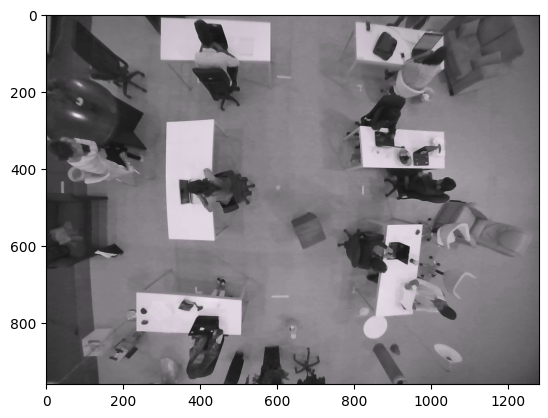

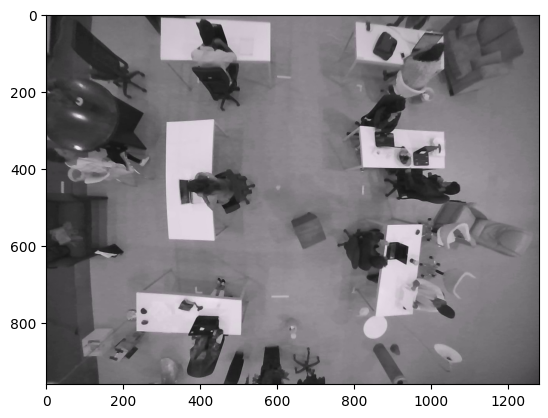

In [13]:
idx = -1

tmp_sim = np.zeros((len(duplicates[idx]), len(duplicates[idx])))
for idx_i, i in enumerate(duplicates[idx]):
    for idx_j, j in enumerate(duplicates[idx]):
        tmp_sim[idx_i, idx_j] = np.round(sim_scores[i, j], 2)

print(tmp_sim)

img_ids = df["id"].values
for i in duplicates[idx]:
    img = img_by_id(img_ids[i], df)
    plt.figure()
    plt.imshow(img)


In [14]:
duplicate_names = []
for tmp_duplicates in duplicates:
    tmp_names = []
    for i in tmp_duplicates:
        row = df[df["id"] == img_ids[i]]
        pth = os.path.join(row["batch"].iloc[0], row["folder"].iloc[0], row["name"].iloc[0])
        tmp_names.append(pth)
    duplicate_names.append(tmp_names)

In [15]:
with open("duplicates.json", "wt") as f:
    json.dump(duplicate_names, f, indent=2)